In [1]:
#from wget import download
import pandas as pd
from os import path, listdir
df_calendar=pd.read_csv("calendar.csv.gz")
df_listings = pd.read_csv("listings (1).csv.gz")

# chequeamos si los archivos están en el directorio donde estamos parados
lista_archivos = listdir("./")
print(f"El contenido de la carpeta es: {lista_archivos}")

El contenido de la carpeta es: ['.git', '.gitignore', 'calendar.csv.gz', 'entrega.ipynb', 'listings (1).csv.gz', 'prueba1.ipynb', 'pruebanub.ipynb', 'README.md']


In [2]:
#copiamos el conjunto para preservarlo
preprocessed_dataset = df_listings.copy()

#borramos columnas con todos sus valores nulos
preprocessed_dataset = preprocessed_dataset.drop('neighborhood_overview', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_since', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_response_time', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_response_rate', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_acceptance_rate', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_thumbnail_url', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_neighbourhood', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_total_listings_count', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_verifications', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('neighbourhood', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('neighbourhood_group_cleansed', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('calendar_updated', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('instant_bookable', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('listing_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_profile_id',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_profile_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_name',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('scrape_id',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('picture_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_id',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('license',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_picture_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_about',axis=1)

#transformacion de variables a dicotomicas
preprocessed_dataset ['source']= preprocessed_dataset['source'].map({"city scrape": True, "previous scrape": False})
preprocessed_dataset ['has_availability']= preprocessed_dataset['has_availability'].map({"t": True, "f": False}).fillna(False).astype(bool)
preprocessed_dataset ['host_is_superhost']= preprocessed_dataset['host_is_superhost'].map({"t": True, "f": False})
preprocessed_dataset ['host_has_profile_pic']= preprocessed_dataset['host_has_profile_pic'].map({"t": True, "f": False})
preprocessed_dataset ['host_identity_verified']= preprocessed_dataset['host_identity_verified'].map({"t": True, "f": False})

preprocessed_dataset['price'] = preprocessed_dataset['price'].str.replace(r'[$,]', '', regex=True).astype(float)


#como vamos a utilizar la variable price para una de nuestras hipotesis eliminamos los valores nulos, ya que no son demasiados y para el analisis que necesitamos hacer no podemos
#reemplazarlos por 0 o por la media
preprocessed_dataset.dropna(subset=['price'],inplace=True)

C:\Users\PC1\AppData\Local\Temp\ipykernel_15692\4006656464.py:42: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  preprocessed_dataset.dropna(subset=['price'],inplace=True)


In [3]:
preprocessed_dataset['price'].describe()

count    2.789300e+04
mean     2.758319e+05
std      3.622302e+06
min      1.215500e+03
25%      7.527457e+04
50%      1.006313e+05
75%      1.404809e+05
max      1.716438e+08
Name: price, dtype: float64

In [4]:
preprocessed_dataset['room_type'].value_counts()

room_type
Entire home/apt    25141
Private room        2485
Hotel room           136
Shared room          131
Name: count, dtype: int64

In [5]:
import numpy as np

# Si room_type es 'Private room', asigna 1; en caso contrario (ej. 'Entire home/apt', etc.), asigna 0
preprocessed_dataset['is_private'] = np.where(preprocessed_dataset['room_type'] == 'Private room', 1, 0)
preprocessed_dataset['is_private'].value_counts()

is_private
0    25408
1     2485
Name: count, dtype: int64

In [6]:
preprocessed_dataset = preprocessed_dataset.dropna(subset=['is_private'])
preprocessed_dataset.info()


<class 'pandas.DataFrame'>
Index: 27893 entries, 0 to 29676
Data columns (total 67 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            27893 non-null  int64  
 1   last_scraped                                  27893 non-null  str    
 2   source                                        27893 non-null  bool   
 3   name                                          27893 non-null  str    
 4   description                                   27232 non-null  str    
 5   hosts_time_as_user_years                      27893 non-null  int64  
 6   hosts_time_as_user_months                     27893 non-null  int64  
 7   hosts_time_as_host_years                      27893 non-null  int64  
 8   hosts_time_as_host_months                     27893 non-null  int64  
 9   host_location                                 21710 non-null  str    
 10  ho

In [7]:
preprocessed_dataset.isna().sum()

id                                                 0
last_scraped                                       0
source                                             0
name                                               0
description                                      661
                                                ... 
calculated_host_listings_count_entire_homes        0
calculated_host_listings_count_private_rooms       0
calculated_host_listings_count_shared_rooms        0
reviews_per_month                               3366
is_private                                         0
Length: 67, dtype: int64

b- Alquilar un espacio entero cuesta, en promedio, más del doble que alquilar
una habitación privada. 
Creamos la variable derivada is_private y tenemos que compararla con el precio 

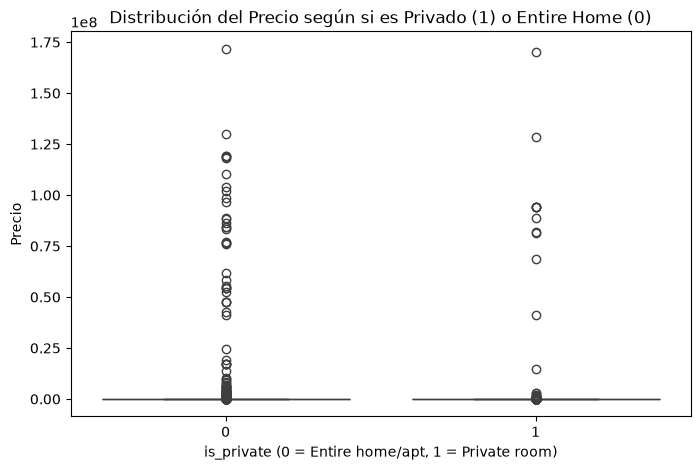

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.boxplot(x='is_private', y='price', data=preprocessed_dataset)
plt.title('Distribución del Precio según si es Privado (1) o Entire Home (0)')
plt.xlabel('is_private (0 = Entire home/apt, 1 = Private room)')
plt.ylabel('Precio')
plt.show()


In [9]:
# 1. Calcular el primer cuartil (Q1) y el tercer cuartil (Q3) de la columna 'price'
Q1 = preprocessed_dataset['price'].quantile(0.25)
Q3 = preprocessed_dataset['price'].quantile(0.75)

# 2. Calcular el Rango Intercuartil (IQR)
IQR = Q3 - Q1

# 3. Definir los límites para considerar un valor como "normal" (generalmente 1.5 * IQR)
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# 4. Filtrar el DataFrame conservando solo los valores dentro de ese rango
preprocessed_dataset_filtrado = preprocessed_dataset[(preprocessed_dataset['price'] >= limite_inferior) & (preprocessed_dataset['price'] <= limite_superior)]

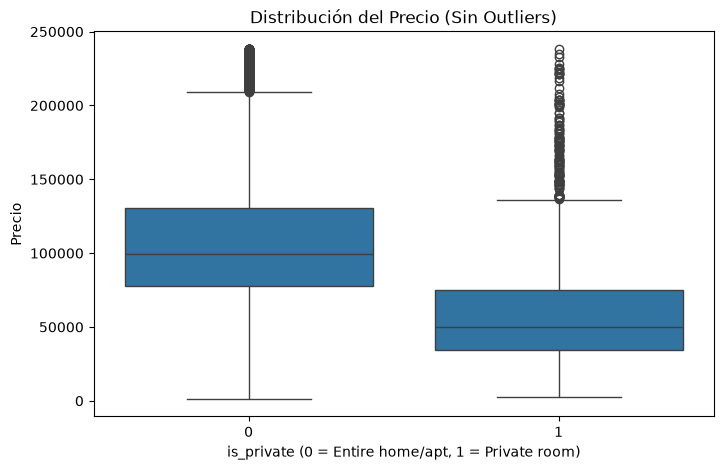

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

# Generamos el boxplot usando los datos limpios
sns.boxplot(x='is_private', y='price', data=preprocessed_dataset_filtrado)

plt.title('Distribución del Precio (Sin Outliers)')
plt.xlabel('is_private (0 = Entire home/apt, 1 = Private room)')
plt.ylabel('Precio')
plt.show()

In [11]:
from scipy.stats import shapiro

# Separamos los datos en dos grupos, desarrollados y en vías de desarrollo
private = preprocessed_dataset[preprocessed_dataset['is_private'] == 1]['price']
entire_home = preprocessed_dataset[preprocessed_dataset['is_private'] == 0]['price']

# Test de Shapiro-Wilk para habitaciones privadas
stat, p = shapiro(private)
print(f"Test de Shapiro-Wilk habitaciones privadas: Estadístico={stat:.3f}, p-valor={p:.3f}")

# Test de Shapiro-Wilk para alojamientos enteros
stat, p = shapiro(entire_home)
print(f"Test de Shapiro-Wilk para alojamientos enteros: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Shapiro-Wilk habitaciones privadas: Estadístico=0.042, p-valor=0.000


Test de Shapiro-Wilk para alojamientos enteros: Estadístico=0.023, p-valor=0.000


c:\Users\PC1\Desktop\tpeCDD\tpeCDD\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 25408.
  res = hypotest_fun_out(*samples, **kwds)


In [ ]:
from scipy.stats import kstest

# Test de Kolmogorov-Smirnov para habitaciones privadas
stat, p = kstest(private, 'norm')
print(f"Test de Kolmogorov-Smirnov para habitaciones privadas: Estadístico={stat:.3f}, p-valor={p:.3f}")

# Test de Kolmogorov-Smirnov para alojamientos enteros
stat, p = kstest(entire_home, 'norm')
print(f"Test de Kolmogorov-Smirnov para alojamientos enteros: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Kolmogorov-Smirnov para habitaciones privadas: Estadístico=1.000, p-valor=0.000
Test de Kolmogorov-Smirnov para alojamientos enteros: Estadístico=1.000, p-valor=0.000


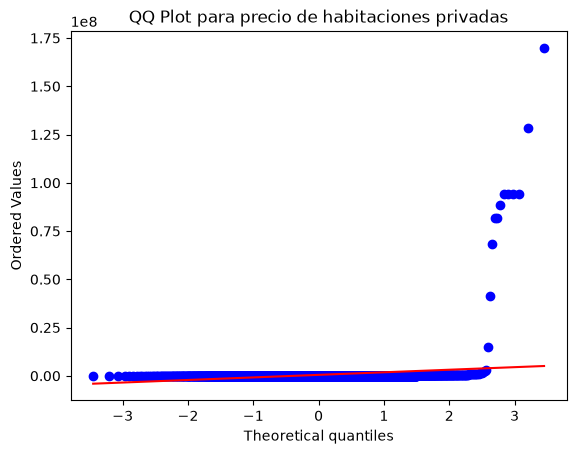

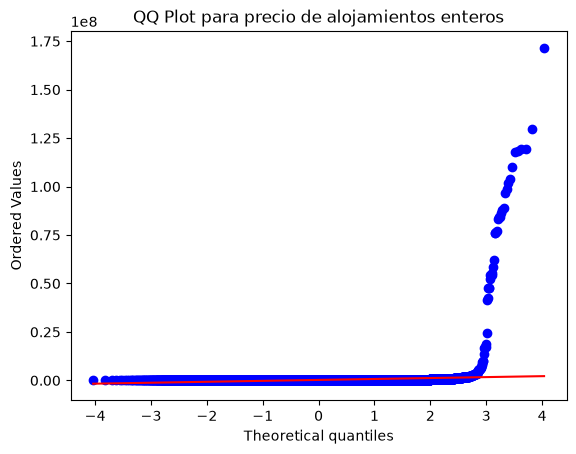

In [13]:
import matplotlib.pyplot as plt
import scipy.stats as stats

# QQ plot habitaciones privadas
stats.probplot(private, dist="norm", plot=plt)
plt.title("QQ Plot para precio de habitaciones privadas")
plt.show()

# QQ plot alojamientos enteros
stats.probplot(entire_home, dist="norm", plot=plt)
plt.title("QQ Plot para precio de alojamientos enteros")
plt.show()

In [14]:
stat, p = stats.levene(private, entire_home)
print(f"Test de Levene para precio: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Levene para precio: Estadístico=14.373, p-valor=0.000


In [15]:
# Test de Kruskal-Wallis para comparar precio entre habitaciones privadas y alojamientos completos
stat, p = stats.kruskal(entire_home, private)
print(f"Test de Kruskal-Wallis para precio: Estadístico={stat:.3f}, p-valor={p:.3f}")

# Interpretación de los resultados
alpha = 0.05  # Nivel de significancia
if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en el precio entre habitaciones privadas y alojamientos enteros.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una diferencia significativa en el precio entre habitaciones privadas y alojamientos enteros.")

Test de Kruskal-Wallis para precio: Estadístico=2618.649, p-valor=0.000
Se rechaza la hipótesis nula.
Existe una diferencia significativa en el precio entre habitaciones privadas y alojamientos enteros.


HIPOTESIS 2 PLANTEADA POR NOSOTROS
-Ser superhost suele subir la cantidad de días de ocupación estimada en un año

Variables: host_is_superhost y availability_365 


In [18]:
preprocessed_dataset['availability_365'].value_counts()

availability_365
365    1833
364     842
363     450
269     424
362     329
       ... 
109      17
107      15
3        10
1         9
0         4
Name: count, Length: 366, dtype: int64

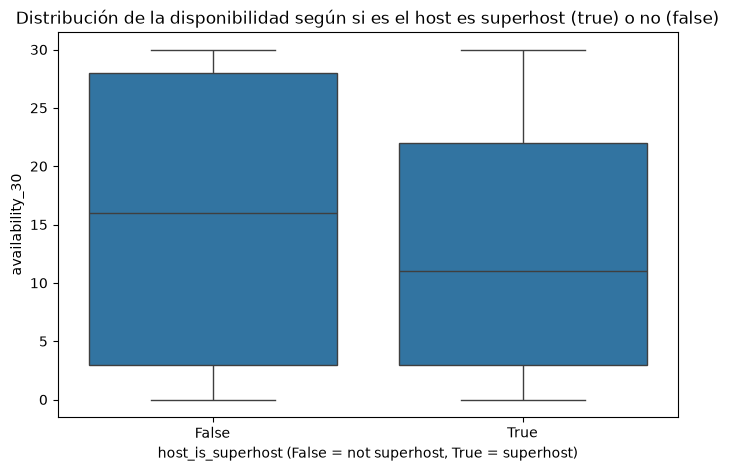

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.boxplot(x='host_is_superhost', y='availability_30', data=preprocessed_dataset)
plt.title('Distribución de la disponibilidad según si es el host es superhost (true) o no (false)')
plt.xlabel('host_is_superhost (False = not superhost, True = superhost)')
plt.ylabel('availability_30')
plt.show()


In [27]:
from scipy.stats import shapiro

# Separamos los datos en dos grupos, desarrollados y en vías de desarrollo
superhost = preprocessed_dataset[preprocessed_dataset['host_is_superhost'] == True]['availability_365']
not_superhost = preprocessed_dataset[preprocessed_dataset['host_is_superhost'] == False]['availability_365']

# Test de Shapiro-Wilk para habitaciones privadas
stat, p = shapiro(superhost)
print(f"Test de Shapiro-Wilk superhost: Estadístico={stat:.3f}, p-valor={p:.3f}")

# Test de Shapiro-Wilk para alojamientos enteros
stat, p = shapiro(not_superhost)
print(f"Test de Shapiro-Wilk no superhost: Estadístico={stat:.3f}, p-valor={p:.3f}")

c:\Users\PC1\Desktop\tpeCDD\tpeCDD\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 11650.
  res = hypotest_fun_out(*samples, **kwds)


Test de Shapiro-Wilk superhost: Estadístico=0.911, p-valor=0.000
Test de Shapiro-Wilk no superhost: Estadístico=0.881, p-valor=0.000


c:\Users\PC1\Desktop\tpeCDD\tpeCDD\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 16243.
  res = hypotest_fun_out(*samples, **kwds)


In [28]:
from scipy.stats import kstest

# Test de Kolmogorov-Smirnov para habitaciones privadas
stat, p = kstest(superhost, 'norm')
print(f"Test de Kolmogorov-Smirnov para superhost: Estadístico={stat:.3f}, p-valor={p:.3f}")

# Test de Kolmogorov-Smirnov para alojamientos enteros
stat, p = kstest(not_superhost, 'norm')
print(f"Test de Kolmogorov-Smirnov para los que no son superhost: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Kolmogorov-Smirnov para superhost: Estadístico=0.999, p-valor=0.000
Test de Kolmogorov-Smirnov para los que no son superhost: Estadístico=0.998, p-valor=0.000


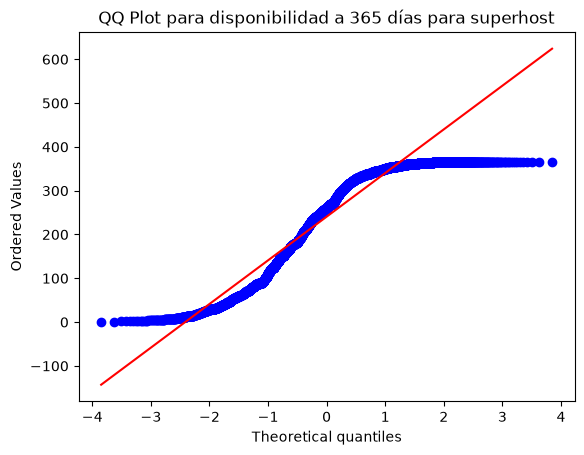

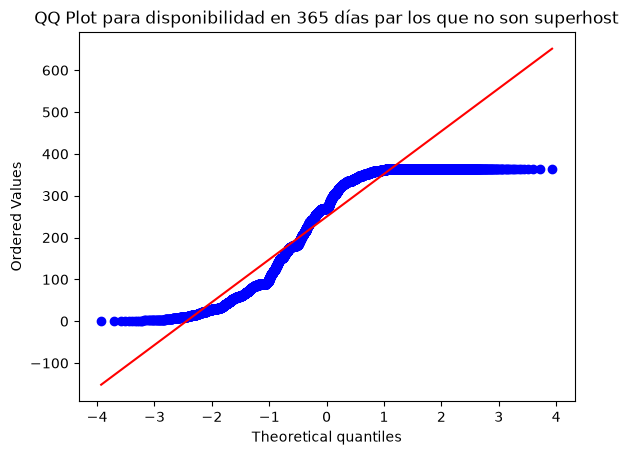

In [29]:
import matplotlib.pyplot as plt
import scipy.stats as stats

stats.probplot(superhost, dist="norm", plot=plt)
plt.title("QQ Plot para disponibilidad a 365 días para superhost")
plt.show()

stats.probplot(not_superhost, dist="norm", plot=plt)
plt.title("QQ Plot para disponibilidad en 365 días par los que no son superhost")
plt.show()


In [30]:
stat, p = stats.levene(superhost, not_superhost)
print(f"Test de Levene para disponibilidad a 365 días: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Levene para disponibilidad a 365 días: Estadístico=30.143, p-valor=0.000


In [ ]:
# Test de Kruskal-Wallis para comparar disponibilidad a 365 dias para superhosts y no superhosts
stat, p = stats.kruskal(superhost, not_superhost)
print(f"Test de Kruskal-Wallis para disponibilidad a 365 días: Estadístico={stat:.3f}, p-valor={p:.3f}")

# Interpretación de los resultados
alpha = 0.05  # Nivel de significancia
if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en la disponibilidad entre superhosts y no superhosts.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una diferencia significativa en la disponibilidad entre superhosts y no superhosts")

Test de Kruskal-Wallis para precio: Estadístico=148.905, p-valor=0.000
Se rechaza la hipótesis nula.
Existe una diferencia significativa en la disponibilidad entre superhosts y no superhosts.
